In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

Load in hydraulic data:

60s cycles where sensors record cooler condition, valve condition, internal pump leakage, hydraulic accumulator, and a stable flag.

In [13]:
data_dir = Path("data/hydraulic")

profile = pd.read_csv(data_dir / "profile.txt", sep="\t", header=None)
profile.columns = ["cooler", "valve", "pump_leak", "accumulator", "stable"]
print(profile.shape) # rows is number of cycles
print(profile["pump_leak"].value_counts()) # how many cycles have no, weak, or severe leaks 

(2205, 5)
pump_leak
0    1221
2     492
1     492
Name: count, dtype: int64


Look at raw data of one temperature sensor:

Rows are cycles, each column is one reading during that cycle, one per second.

(2205, 60)


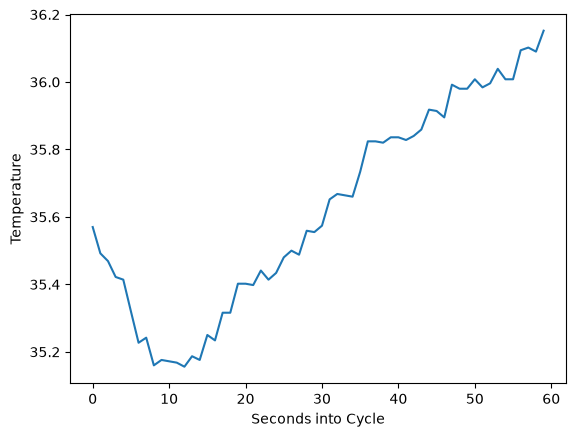

In [14]:
ts1 = pd.read_csv(data_dir / "TS1.txt", sep="\t", header=None).to_numpy()

print(ts1.shape)
plt.plot(ts1[0]) # plot the first cycle
plt.xlabel("Seconds into Cycle")
plt.ylabel("Temperature")
plt.show()

Turn cycles of a sensor into summary values of mean, std, and slope

In [15]:
cycle = ts1[0]
t = np.arange(len(cycle))
print(cycle.mean())
print(cycle.std())
print(np.polyfit(t, cycle, 1)[0])

35.62198333333333
0.30565048076011453
0.01626993609335999


In [16]:
t = np.arange(ts1.shape[1])

means = ts1.mean(axis=1)
stds = ts1.std(axis=1)
slopes = np.polyfit(t, ts1.T, 1)[0]

print(means.shape, stds.shape, slopes.shape)
print(means[0], stds[0], slopes[0])

(2205,) (2205,) (2205,)
35.62198333333334 0.3056504807601146 0.01626993609335994


Repeated on all sensors

In [19]:
sensors = ["PS1", "PS2", "PS3", "PS4", "PS5", "PS6", "EPS1", "FS1", "FS2",
                "TS1", "TS2", "TS3", "TS4", "VS1", "CE", "CP", "SE"]

features = {} # lookup table for features, keys are column names, values are lists 
for sensor in sensors:
    readings = pd.read_csv(data_dir / (sensor + ".txt"), sep="\t", header=None).to_numpy()
    t = np.arange(readings.shape[1])
    features[sensor + "_mean"] = readings.mean(axis=1) # one number for each row (a cycle)
    features[sensor + "_std"] = readings.std(axis=1)
    features[sensor + "_slope"] = np.polyfit(t, readings.T, 1)[0]

X = pd.DataFrame(features)

print(X.shape) # each sensor has 3 columns
print(X.columns[:6].tolist())
print(X["TS1_mean"][0])

(2205, 51)
['PS1_mean', 'PS1_std', 'PS1_slope', 'PS2_mean', 'PS2_std', 'PS2_slope']
35.62198333333334


Transform pump labels into leak and no leak

In [20]:
y = (profile["pump_leak"] >= 1).astype(int)

print(y.value_counts())
print(y.mean())
print(len(X) == len(y))

pump_leak
0    1221
1     984
Name: count, dtype: int64
0.44625850340136053
True


Split data for training and testing, and create a baseline

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline.score(X_test, y_test)

(1764, 51) (441, 51)
0.44614512471655327 0.4467120181405896


0.5532879818594104